In [5]:
import numpy as np
import matplotlib.pyplot as plt
from dspeed.processors import inject_gumbel
from lgdo.types import ArrayOfEqualSizedArrays, WaveformTable
from scipy.integrate import simpson
from matplotlib.cm import get_cmap

#from pulse_sorting import *


In [6]:
# # Generate waveforms and plot differences
# wf_tab, t0s = wf_generator(num_wfs=1000)

# i, j = 50, 100
# wf1 = wf_tab.values.nda[i]
# wf2 = wf_tab.values.nda[j]
# dt = wf_tab.dt[0]

# sign, magnitude = analyze_waveform_pair(wf1, wf2, dt)
# print(f"Sign of pre-integral: {sign}")
# print(f"Total integral magnitude: {magnitude:.3f}")

In [7]:
# # Generate waveforms
# wf_tab, _ = wf_generator(num_wfs=1000)

# # Reorder based on similarity
# reordered_wf_tab, reordered_matrix, sorted_row_sums = reorder_waveforms_by_similarity(wf_tab)

# # View the results
# print("Sorted Row Sums:", np.round(sorted_row_sums, 2))
# print("Reordered Comparison Matrix:\n", np.round(reordered_matrix, 2))

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from dspeed.processors import inject_gumbel
from lgdo.types import ArrayOfEqualSizedArrays, WaveformTable
from scipy.integrate import simpson
from matplotlib.cm import get_cmap


# --- Waveform generator ---
def wf_generator(num_wfs=1000, amplitude=1000, width=1, t0_start=11, jitter=1, wf_len=32, signal_to_noise=1000, period=5):
    mean = 0
    std = amplitude / signal_to_noise
    empty_wfs = np.random.normal(mean, std, size=(num_wfs, wf_len))
    wfs = np.zeros_like(empty_wfs)
    t0s = np.random.uniform(t0_start, t0_start + jitter, num_wfs)

    for i in range(num_wfs):
        inject_gumbel(empty_wfs[i, :], amplitude, t0s[i], width, wfs[i, :]) 
    
    wf_tab = WaveformTable(values=wfs, dt=period, dt_units="ns", t0=0, t0_units="ns")
    return wf_tab, t0s

def analyze_waveform_pair(wf1, wf2):
    """
    Analyze the difference between two waveforms.

    Parameters:
    - wf1, wf2: 1D numpy arrays of waveform data
    - dt: time step between samples

    Returns:
    - sign (int): +1 if pre-integral is positive, -1 if negative
    - total_magnitude (float): sum of absolute values of integrals
    """
    wf1 = 1/np.sqrt(np.sum(wf1)) * wf1
    wf2 = 1/np.sqrt(np.sum(wf2)) * wf2

    # Find sign of crossing
    diff = wf1 - wf2
    sign = 1 if np.argmax(diff)<= np.argmin(diff) else -1
    
    # Find the size of the difference between the wfs
    # norm = 1 #np.sqrt(np.sum(wf1**2))*np.sqrt(np.sum(wf2**2))
    # diffsq = 1/norm * diff**2
    magnitude = 1#simpson(diffsq)

    return sign * magnitude

def compute_comparison_matrix_sum(wf_tab):
    """
    Create a matrix where each entry (i, j) is:
    sign * magnitude. 
    
    Diagonal entries are 0.

    Parameters:
    - wf_tab: WaveformTable

    Returns:
    - matrix: 2D numpy array of shape (num_waveforms, num_waveforms)
    """
    wfs = wf_tab.values.nda
    dt = wf_tab.dt[0]
    num_wfs = len(wfs)
    matrix = np.zeros((num_wfs, num_wfs))
    wf_num = len(wfs)

    for i in range(num_wfs):
        for j in range(num_wfs):
            if i == j:
                continue  # Leave diagonal as 0
            try:
                matrix[i, j] = analyze_waveform_pair(wfs[i], wfs[j])
            except ValueError:
                matrix[i, j] = 0  # In case there's no zero-crossing, assign 0 or NaN if preferred

    row_sums = np.sum(matrix, axis=1)
    row_sums_norm = row_sums/wf_num

    return row_sums

def reorder_waveforms_by_fom(wf_tab, fom):
    # Step 3: Get sorted indices (descending)
    sorted_indices = np.argsort(fom)[::-1]

    # Step 4: Reorder the waveforms and matrix
    reordered_wfs = wf_tab.values.nda[sorted_indices]

    # Step 5: Create new WaveformTable with reordered data
    reordered_wf_tab = WaveformTable(
        values=reordered_wfs,
        dt=wf_tab.dt[0],
        dt_units="ns",
        t0=wf_tab.t0[0],
        t0_units="ns"
    )

    return reordered_wf_tab


def plot_waveforms_rainbow(wf_tab):
    """
    Plot all waveforms in the WaveformTable using a rainbow gradient for color. If waveforms are ordered this will produce a rainbow gradient. 

    Parameters:
    - wf_tab: WaveformTable
    """
    wfs = wf_tab.values.nda
    dt = wf_tab.dt[0]
    t = np.linspace(0, len(wfs[0]) * dt, len(wfs[0]))
    num_wfs = len(wfs)

    # Get rainbow colormap
    cmap = get_cmap('rainbow')

    plt.figure(figsize=(22, 9))

    for i, wf in enumerate(wfs):
        color = cmap(i / num_wfs)
        plt.plot(t, wf, '.', color=color, linewidth=1)

    # plt.title("RWaveforms", fontsize=14)
    plt.xlabel(r"\textbf{Time (ns)}")
    plt.ylabel(r"\textbf{Amplitude}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def reorder_waveforms_by_similarity(wf_tab):
    """
    Reorders waveforms based on similarity scores from the comparison matrix row sums.

    Returns:
    - reordered_wf_tab: WaveformTable with reordered waveforms
    - reordered_matrix: Comparison matrix reordered accordingly
    - sorted_row_sums: 1D array of sorted row sums
    """
    # Step 1: Compute the comparison matrix
    row_sums = compute_comparison_matrix_sum(wf_tab)

    # Step 3: Get sorted indices (descending)
    sorted_indices = np.argsort(row_sums)[::-1]

    # Step 4: Reorder the waveforms and matrix
    reordered_wfs = wf_tab.values.nda[sorted_indices]

    # Step 5: Create new WaveformTable with reordered data
    reordered_wf_tab = WaveformTable(
        values=reordered_wfs,
        dt=wf_tab.dt[0],
        dt_units="ns",
        t0=wf_tab.t0[0],
        t0_units="ns"
    )

    return reordered_wf_tab

def upsampled_template_waveform(
    wfs_in: WaveformTable, upsample_factor: int = 5
) -> WaveformTable:
    """
    Builds an upsampled template waveform by:
    - Splitting already-sorted waveforms into groups
    - Shifting each group backward to align in time (based on group index)
    - Averaging each group
    - Interleaving group averages to simulate upsampling

    Parameters
    ----------
    wfs_in : WaveformTable
        The sorted waveforms (earliest to latest).
    upsample_factor : int
        The number of groups and desired upsampling factor.

    Returns
    -------
    wf_template : WaveformTable
        The upsampled, aligned template waveform.
    """

    if not isinstance(upsample_factor, int) or upsample_factor < 1:
        raise ValueError("Upsample factor must be a positive integer")

    sorted_wfs = wfs_in.values.nda
    dt = wfs_in.dt.nda[0]
    wf_len = sorted_wfs.shape[1]

    # Initialize with zeros
    wf_extended = np.zeros(wf_len * upsample_factor)
    counts = np.zeros(wf_len * upsample_factor)

    # Split waveforms into `upsample_factor` groups
    groups = np.array_split(sorted_wfs, upsample_factor)[::-1]
    x = np.arange(wf_len)
    #return groups
    for n, group in enumerate(groups):
        avg = group.mean(axis=0)
        #for i in range(wf_len):
        wf_extended[np.arange(0, wf_len* upsample_factor,upsample_factor )+n] = avg

    final_waveform = wf_extended

    return WaveformTable(
        values=ArrayOfEqualSizedArrays(nda=final_waveform),
        dt=dt / upsample_factor,
        t0=0,
        t0_units=wfs_in.t0_units,
    )

def reorder_and_upsample(wf_tab, fom, upsample=5):
    reordered_wfs = reorder_waveforms_by_fom(wf_tab, fom)
    upsampled_wfs = upsampled_template_waveform(reordered_wfs, upsample)

    return upsampled_wfs

/var/folders/ch/dytr8n99541626ftf95bnnq40000gn/T/ipykernel_95564/12117427.py:114: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('rainbow')


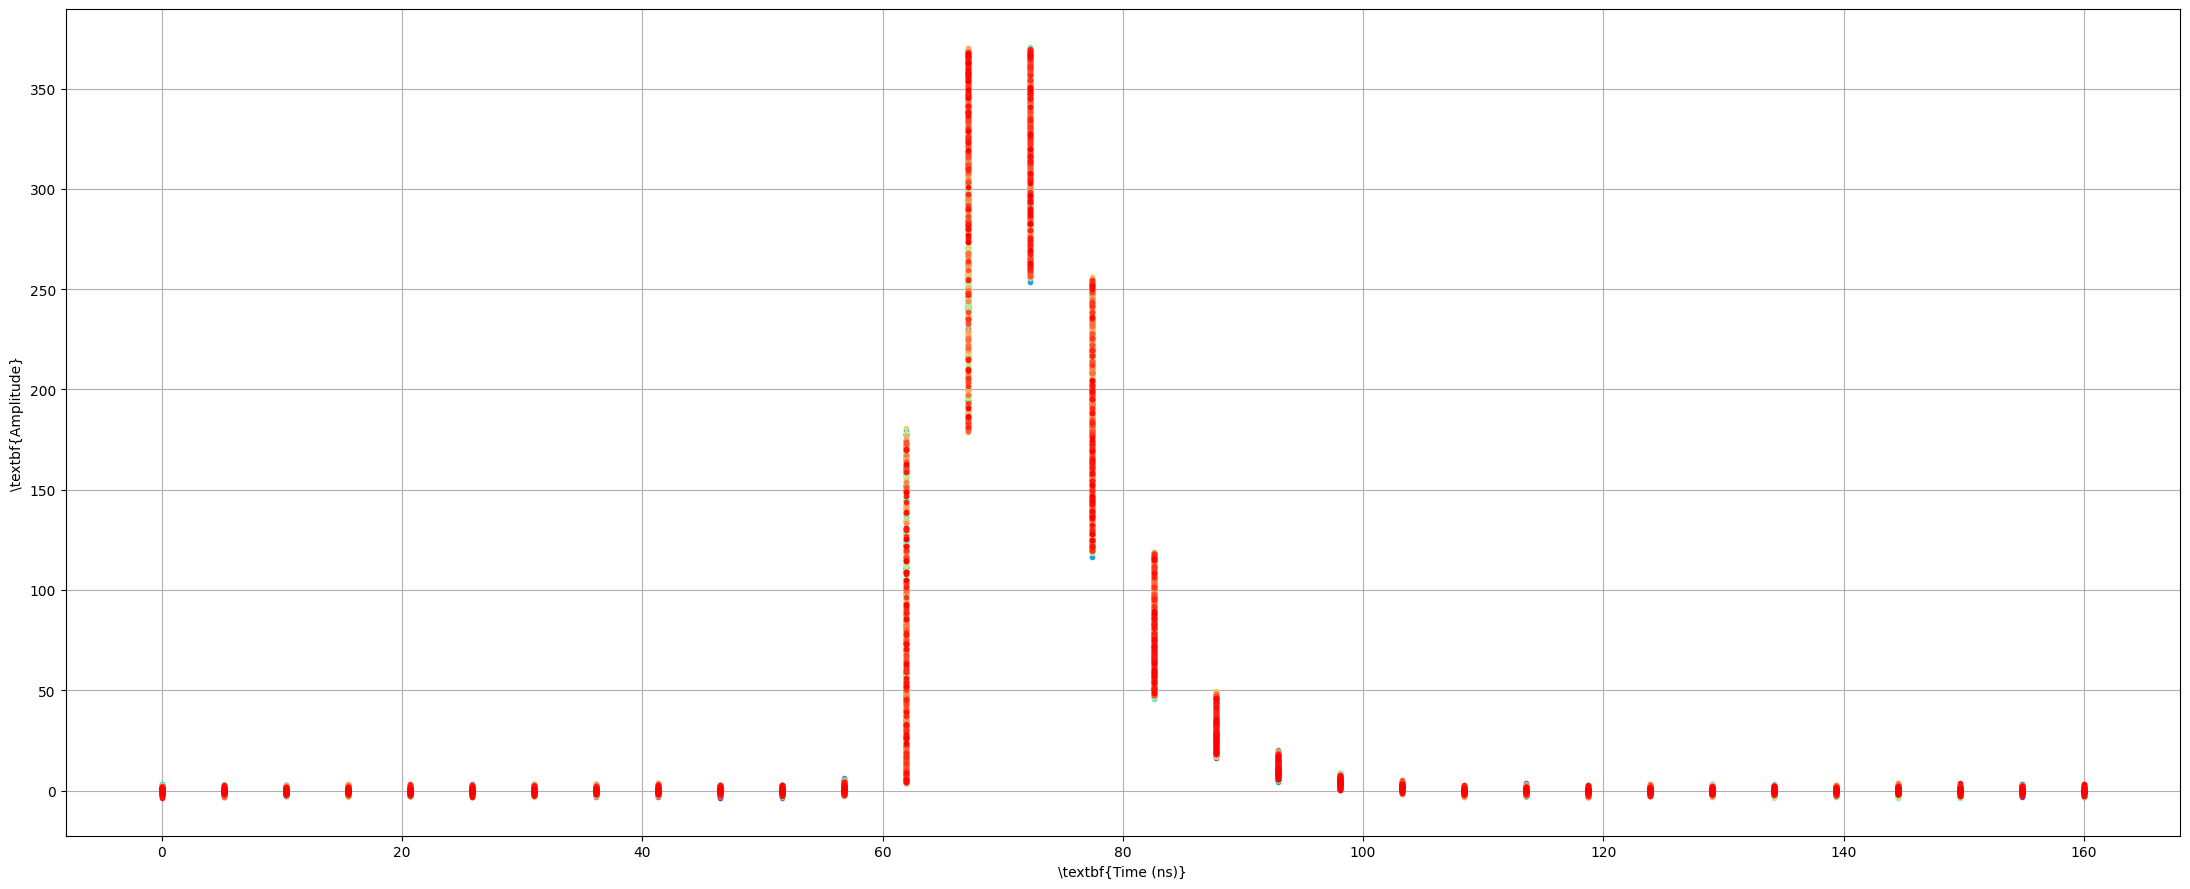

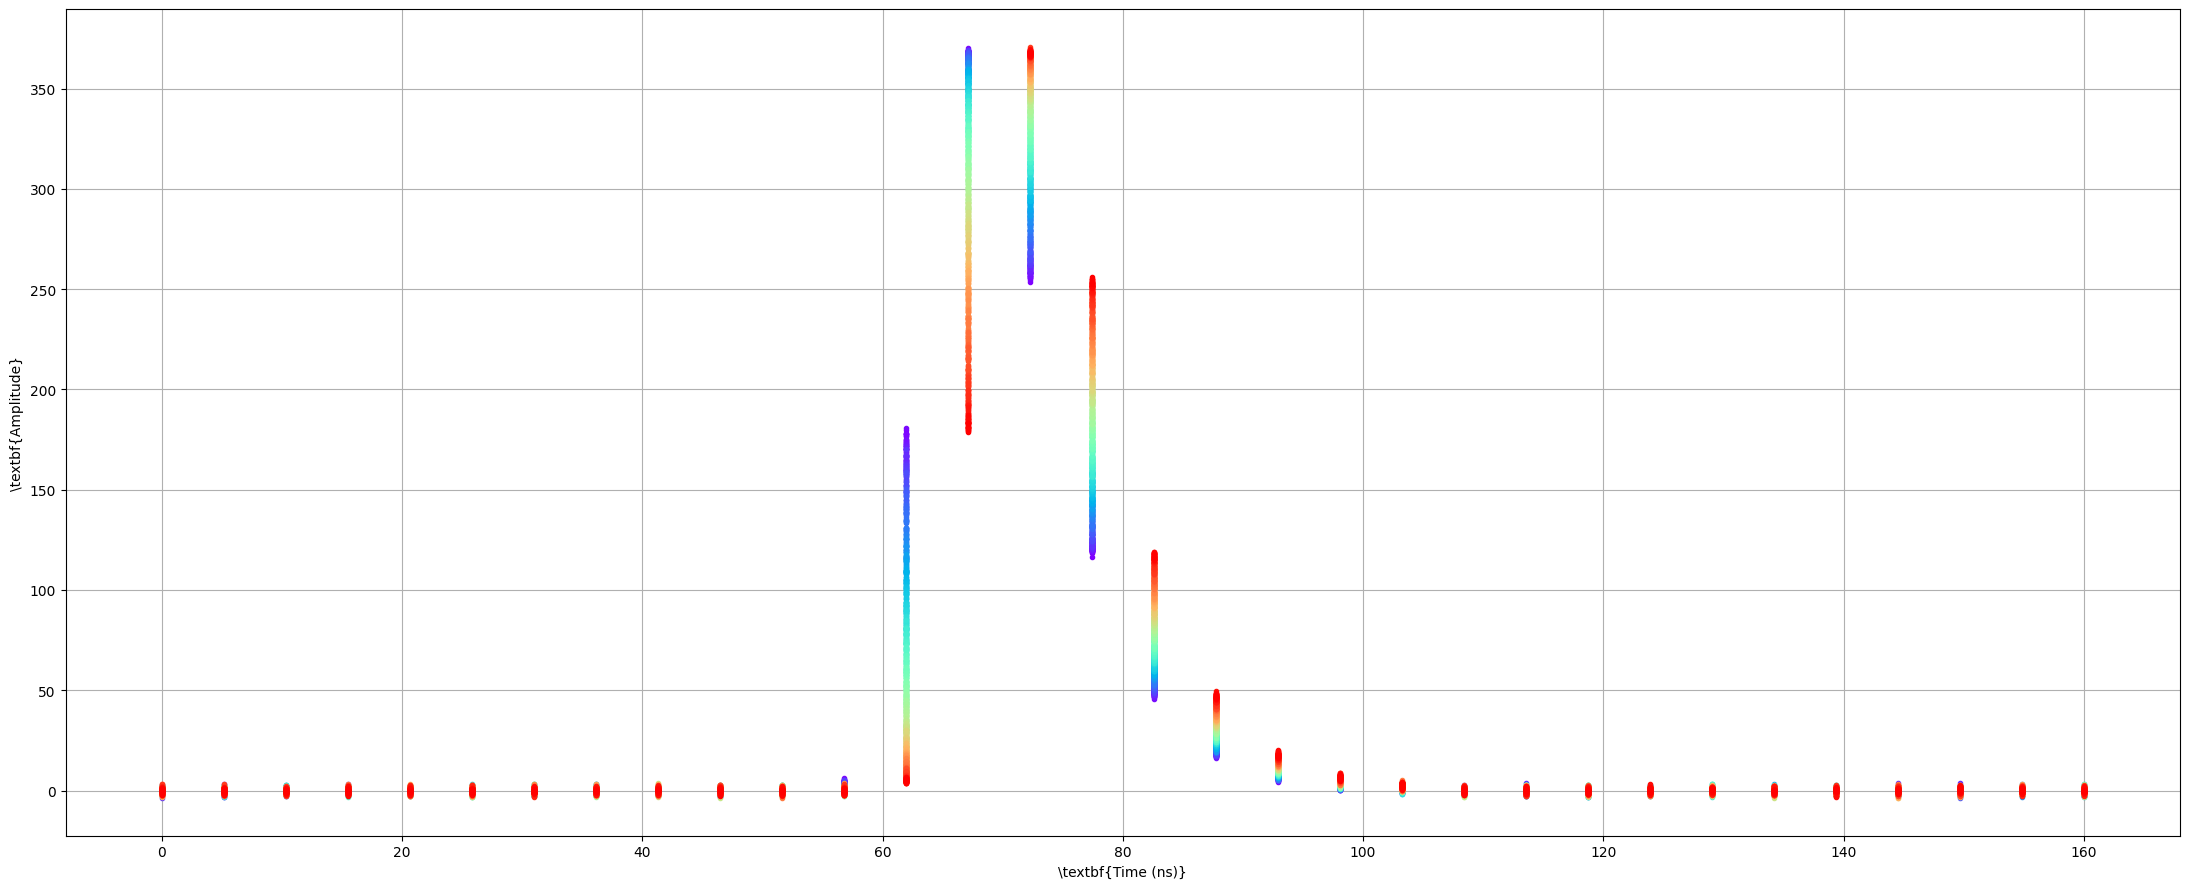

In [71]:
# Generate and reorder waveforms
wf_tab, t0s = wf_generator() 
reordered_wf_tab = reorder_waveforms_by_similarity(wf_tab) #, reordered_matrix, sorted_row_sums

# Plot them in rainbow color before reordering
plot_waveforms_rainbow(wf_tab)

# Plot with rainbow coloring
plot_waveforms_rainbow(reordered_wf_tab)

In [72]:
# --- Parameters ---
upsample_factor = 5  # You can change this to any desired factor

# --- Build upsampled waveform template ---
groups = upsampled_template_waveform(
    wfs_in=reordered_wf_tab,  # <- Replace with your actual variable name if different
    upsample_factor=upsample_factor
)

In [73]:
plt.figure()
for i,group in enumerate(groups):
    plt.plot(np.arange(0, 32*5,5) + i  ,np.mean(group, axis=0), ls="", marker="o")
plt.show()

AxisError: axis 0 is out of bounds for array of dimension 0

<Figure size 640x480 with 0 Axes>

In [ ]:
groups

In [ ]:
# --- Parameters ---
upsample_factor = 5  # You can change this to any desired factor

# --- Build upsampled waveform template ---
template_wf_table = upsampled_template_waveform(
    wfs_in=reordered_wf_tab,  # <- Replace with your actual variable name if different
    upsample_factor=upsample_factor
)

# --- Extract waveform and time axis for plotting ---
template_wf = template_wf_table.values.nda
print(template_wf)
# dt = template_wf_table.dt.nda[0]
# time_axis = np.arange(len(template_wf)) * dt


plt.figure(figsize=(12, 6))
plt.plot(template_wf,'.')
plt.title(f"Upsampled Template (x{upsample_factor})")
# plt.xlabel("Time")
# plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
def plot_waveform_variation(
    variable_name,
    values_to_try,
    fixed_params=None
):
    """
    Plots upsampled waveform templates on a single plot while varying one parameter.

    Parameters:
        variable_name (str): Name of the parameter to vary. Must be one of:
            'num_wfs', 'jitter', 'signal_to_noise', 'upsample_factor'
        values_to_try (list): List of values for the selected variable.
        fixed_params (dict): Optional. Dictionary of other fixed parameters.
    """
    # Default fixed parameters
    default_params = {
        "num_wfs": 1000,
        "jitter": 1,
        "signal_to_noise": 10000,
        "upsample_factor": 5,
        "amplitude": 1000,
        "width": 1,
        "t0_start": 11,
        "wf_len": 32,
        "period": 5,
    }

    if fixed_params:
        default_params.update(fixed_params)

    plt.figure(figsize=(10, 6))

    for val in values_to_try:
        # Update the variable being tested
        params = default_params.copy()
        params[variable_name] = val

        # --- Generate and reorder waveforms ---
        wf_tab, _ = wf_generator(
            num_wfs=params["num_wfs"],
            amplitude=params["amplitude"],
            width=params["width"],
            t0_start=params["t0_start"],
            jitter=params["jitter"],
            wf_len=params["wf_len"],
            signal_to_noise=params["signal_to_noise"],
            period=params["period"]
        )
        reordered_wf_tab = reorder_waveforms_by_similarity(wf_tab)

        # --- Upsample ---
        template_wf_table = upsampled_template_waveform(
            wfs_in=reordered_wf_tab,
            upsample_factor=params["upsample_factor"]
        )
        template_wf = template_wf_table.values.nda

        # --- Plot ---
        plt.plot(template_wf, '.', markersize=2, label=f"{variable_name} = {val}")

    plt.title(f"Effect of Varying '{variable_name}' on Template", fontsize=14)
    plt.xlabel("Upsampled Time")
    plt.ylabel("Amplitude")
    plt.legend(title=variable_name)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
default_params = {
        "num_wfs": 1000,
        "jitter": 1,
        "signal_to_noise": 10000,
        "upsample_factor": 5,
        "amplitude": 1000,
        "width": 1,
        "t0_start": 11,
        "wf_len": 32,
        "period": 5,
    }

In [ ]:
wf_tab, _ = wf_generator(
            num_wfs=default_params["num_wfs"],
            amplitude=default_params["amplitude"],
            width=default_params["width"],
            t0_start=default_params["t0_start"],
            jitter=default_params["jitter"],
            wf_len=default_params["wf_len"],
            signal_to_noise=20,
            period=default_params["period"]
        )
reordered_wf_tab = reorder_waveforms_by_similarity(wf_tab)

# --- Upsample ---
template_wf_table = upsampled_template_waveform(
    wfs_in=reordered_wf_tab,
    upsample_factor=default_params["upsample_factor"]
)
template_wf = template_wf_table.values.nda

In [ ]:
plt.figure()
plt.step(np.arange(0,len(template_wf),1),template_wf)
plt.xlim([40,100])
plt.show()

/var/folders/ch/dytr8n99541626ftf95bnnq40000gn/T/ipykernel_95564/12117427.py:36: RuntimeWarning: invalid value encountered in sqrt
  wf2 = 1/np.sqrt(np.sum(wf2)) * wf2
/var/folders/ch/dytr8n99541626ftf95bnnq40000gn/T/ipykernel_95564/12117427.py:35: RuntimeWarning: invalid value encountered in sqrt
  wf1 = 1/np.sqrt(np.sum(wf1)) * wf1


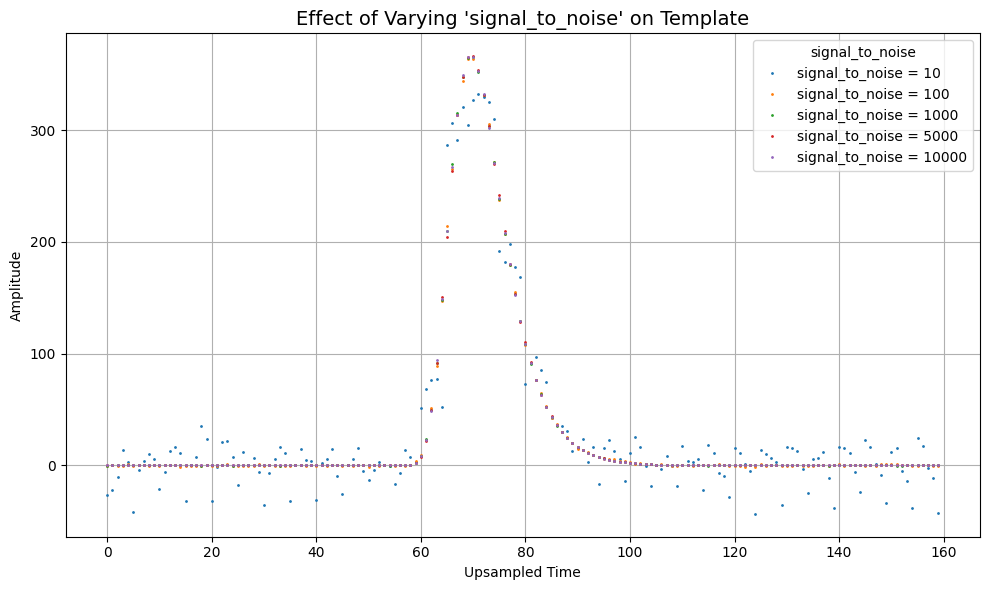

In [74]:
# Vary signal-to-noise ratio with custom fixed parameters
plot_waveform_variation(
    variable_name="signal_to_noise",
    values_to_try=[10, 100, 1000, 5000, 10000]
)

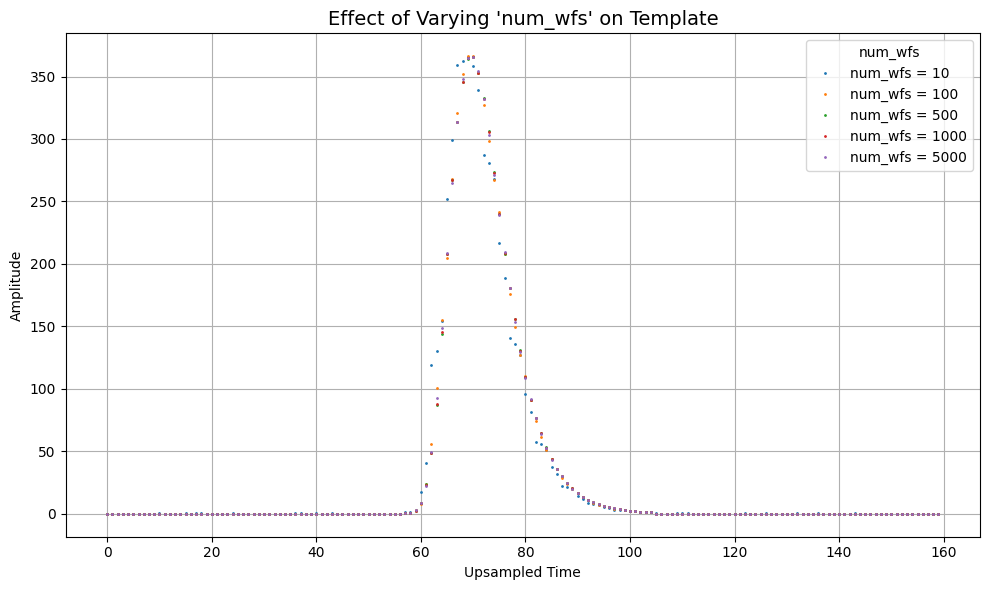

In [75]:
plot_waveform_variation(
    variable_name="num_wfs",
    values_to_try=[10, 100, 500, 1000, 5000]
)

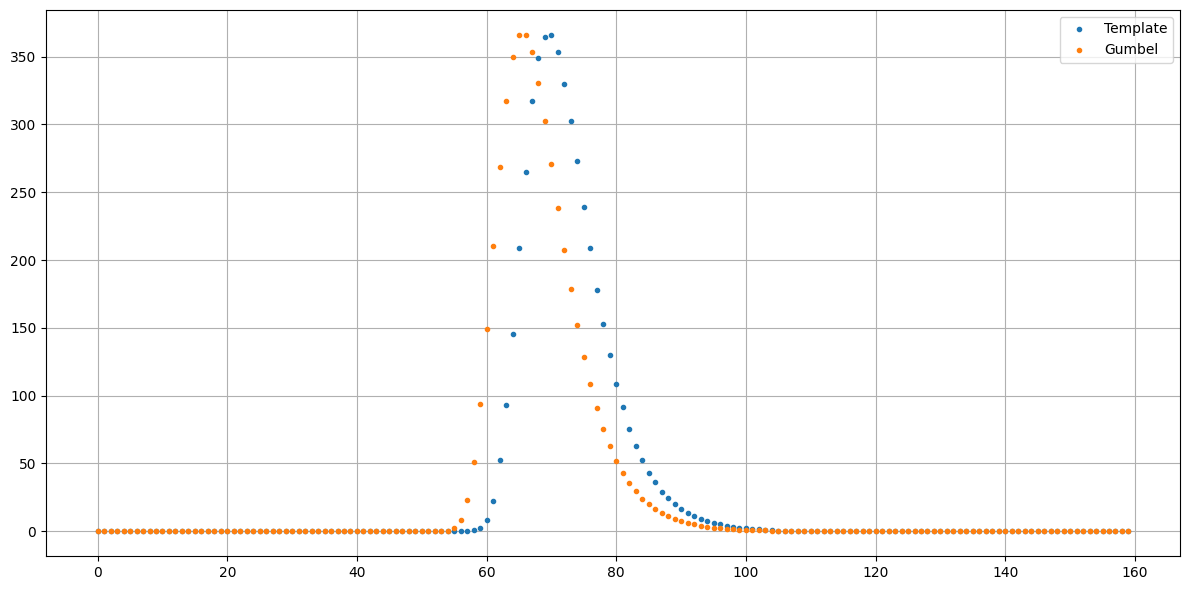

In [76]:
gumbel = np.zeros_like(template_wf)
inject_gumbel(gumbel, 5 * 1000, 55.5, 1 * 5, gumbel)

plt.figure(figsize=(12, 6))
plt.plot(template_wf,'.', label="Template")
plt.plot(gumbel, '.', label="Gumbel")
# plt.title(f"Upsampled Template (x{upsample_factor})")
# plt.xlabel("Time")
# plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
